<a href="https://colab.research.google.com/github/bavucadoz/244107020162_ML_2026/blob/main/Minggu09/TG9_2_244107020162_AryaBayuSamodra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas 2**


---



In [1]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv('spam.csv', encoding='latin-1')
df = df.drop(df.iloc[:, 2:], axis=1)
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

new_labels = {
    'spam': 1,
    'ham': 0
}

df['Labels'] = df['Labels'].map(new_labels)

df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
X = df['SMS'].values
y = df['Labels'].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

print(f'Total data train: {len(X_train_raw)}')
print(f'Total data test : {len(X_test_raw)}')


Total data train: 4457
Total data test : 1115




---


**Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan:**
- menggunakan data `spam.csv`.
- Fitur `CountVectorizer` dengan mengaktifkan `stop_words`.
- Evaluasi hasilnya.

In [4]:
# Ekstraksi fitur CountVectorizer dengan stop_words='english'

cv = CountVectorizer(stop_words='english')

X_train_cv = cv.fit_transform(X_train_raw)
X_test_cv = cv.transform(X_test_raw)

print(f'Jumlah vocab: {len(cv.get_feature_names_out())}')
print(f'Dimensi data train: {X_train_cv.shape}')
print(f'Dimensi data test : {X_test_cv.shape}')

Jumlah vocab: 7466
Dimensi data train: (4457, 7466)
Dimensi data test : (1115, 7466)


In [5]:
# Inisialisasi dan training model MNB
mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)

# Prediksi data train & test
y_pred_train_cv = mnb_cv.predict(X_train_cv)
y_pred_test_cv = mnb_cv.predict(X_test_cv)

# Hitung akurasi
acc_train_cv = accuracy_score(y_train, y_pred_train_cv)
acc_test_cv = accuracy_score(y_test, y_pred_test_cv)

print(f'Akurasi Train (CountVectorizer): {acc_train_cv:.4f} ({acc_train_cv*100:.2f}%)')
print(f'Akurasi Test  (CountVectorizer): {acc_test_cv:.4f} ({acc_test_cv*100:.2f}%)')


Akurasi Train (CountVectorizer): 0.9946 (99.46%)
Akurasi Test  (CountVectorizer): 0.9830 (98.30%)


=== Classification Report: CountVectorizer ===
              precision    recall  f1-score   support

     Ham (0)     0.9835    0.9969    0.9901       954
    Spam (1)     0.9797    0.9006    0.9385       161

    accuracy                         0.9830      1115
   macro avg     0.9816    0.9487    0.9643      1115
weighted avg     0.9829    0.9830    0.9827      1115



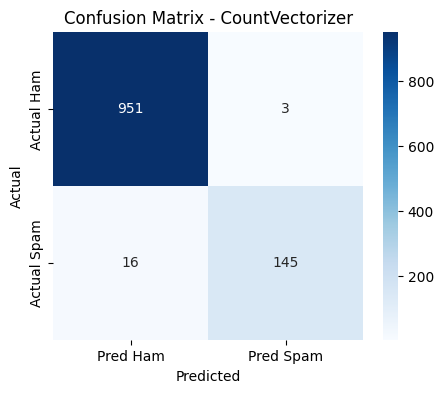

In [6]:
# Evaluasi detail: Classification Report & Confusion Matrix

print('=== Classification Report: CountVectorizer ===')
print(classification_report(y_test, y_pred_test_cv, target_names=['Ham (0)', 'Spam (1)'], digits=4))

cm_cv = confusion_matrix(y_test, y_pred_test_cv)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Ham', 'Pred Spam'],
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.title('Confusion Matrix - CountVectorizer')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()



---

**Buatlah model klasifikasi Multinomial Naive Bayes dengan ketentuan:**

- Menggunakan data `spam.csv`

- Fitur `TF-IDF` dengan mengaktifkan `stop_words`

- Evaluasi hasilnya dan bandingkan dengan hasil pada sebelumnya.

- Berikan kesimpulan fitur mana yang terbaik pada kasus data `spam.csv`

In [7]:
# Ekstraksi fitur TfidfVectorizer dengan stop_words='english'

tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(X_train_raw)
X_test_tfidf = tfidf.transform(X_test_raw)

print(f'Jumlah vocab: {len(tfidf.get_feature_names_out())}')
print(f'Dimensi data train: {X_train_tfidf.shape}')
print(f'Dimensi data test : {X_test_tfidf.shape}')

Jumlah vocab: 7466
Dimensi data train: (4457, 7466)
Dimensi data test : (1115, 7466)


In [8]:
# Inisialisasi dan training model MNB
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

# Prediksi data train & test
y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)

# Hitung akurasi
acc_train_tfidf = accuracy_score(y_train, y_pred_train_tfidf)
acc_test_tfidf = accuracy_score(y_test, y_pred_test_tfidf)

print(f'Akurasi Train (TF-IDF): {acc_train_tfidf:.4f} ({acc_train_tfidf*100:.2f}%)')
print(f'Akurasi Test  (TF-IDF): {acc_test_tfidf:.4f} ({acc_test_tfidf*100:.2f}%)')

Akurasi Train (TF-IDF): 0.9843 (98.43%)
Akurasi Test  (TF-IDF): 0.9605 (96.05%)


=== Classification Report: TF-IDF ===
              precision    recall  f1-score   support

     Ham (0)     0.9559    1.0000    0.9775       954
    Spam (1)     1.0000    0.7267    0.8417       161

    accuracy                         0.9605      1115
   macro avg     0.9780    0.8634    0.9096      1115
weighted avg     0.9623    0.9605    0.9579      1115



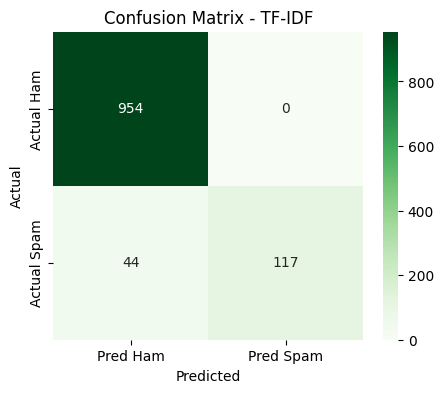

In [9]:
# Evaluasi detail: Classification Report & Confusion Matrix

print('=== Classification Report: TF-IDF ===')
print(classification_report(y_test, y_pred_test_tfidf, target_names=['Ham (0)', 'Spam (1)'], digits=4))

cm_tfidf = confusion_matrix(y_test, y_pred_test_tfidf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Pred Ham', 'Pred Spam'],
            yticklabels=['Actual Ham', 'Actual Spam'])
plt.title('Confusion Matrix - TF-IDF')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Rangkum metrik ke DataFrame
summary_data = {
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Akurasi Train': [acc_train_cv, acc_train_tfidf],
    'Akurasi Test': [acc_test_cv, acc_test_tfidf],
    'Precision (Spam)': [
        precision_score(y_test, y_pred_test_cv, pos_label=1),
        precision_score(y_test, y_pred_test_tfidf, pos_label=1)
    ],
    'Recall (Spam)': [
        recall_score(y_test, y_pred_test_cv, pos_label=1),
        recall_score(y_test, y_pred_test_tfidf, pos_label=1)
    ],
    'F1-Score (Spam)': [
        f1_score(y_test, y_pred_test_cv, pos_label=1),
        f1_score(y_test, y_pred_test_tfidf, pos_label=1)
    ]
}

df_summary = pd.DataFrame(summary_data)
df_summary

,Metode,Akurasi Train,Akurasi Test,Precision (Spam),Recall (Spam),F1-Score (Spam)
0,CountVectorizer,0.994615,0.982960,0.97973,0.900621,0.938511
1,TF-IDF,0.984294,0.960538,1.00000,0.726708,0.841727


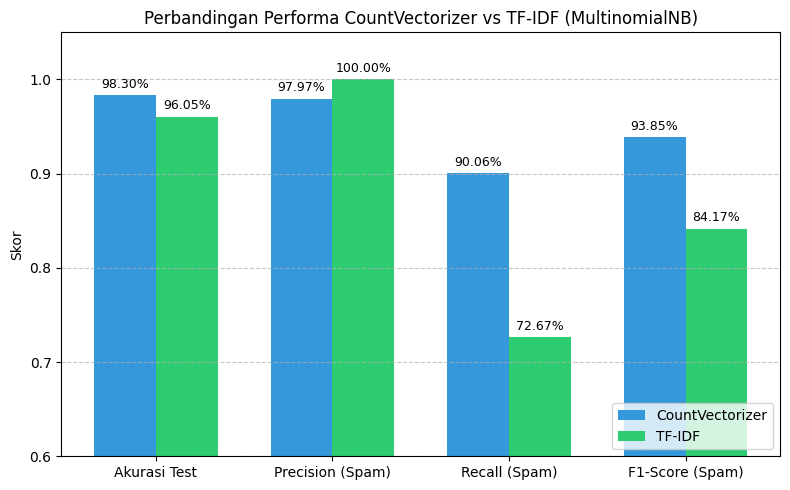

In [11]:
# Visualisasi perbandingan metrik evaluasi

metrics = ['Akurasi Test', 'Precision (Spam)', 'Recall (Spam)', 'F1-Score (Spam)']
cv_vals = df_summary.loc[0, metrics].values
tfidf_vals = df_summary.loc[1, metrics].values

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, cv_vals, width, label='CountVectorizer', color='#3498db')
rects2 = ax.bar(x + width/2, tfidf_vals, width, label='TF-IDF', color='#2ecc71')

ax.set_ylabel('Skor')
ax.set_title('Perbandingan Performa CountVectorizer vs TF-IDF (MultinomialNB)')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.6, 1.05)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.2%}',
                xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()



---

**Kesimpulan:**

Berdasarkan grafik perbandingan performa, `CountVectorizer` adalah fitur yang terbaik secara keseluruhan untuk mengklasifikasikan data `spam.csv` dengan model Multinomial Naive Bayes.

- Akurasi Keseluruhan `(Akurasi Test)`: CountVectorizer mengungguli TF-IDF dengan skor akurasi 98,30% berbanding 96,05%.

- Keseimbangan Model `(F1-Score)`: CountVectorizer memiliki nilai F1-Score yang jauh lebih tinggi yaitu 93,85%, dibandingkan TF-IDF yang hanya mencapai 84,17%. Hal ini menunjukkan CountVectorizer lebih stabil dalam menyeimbangkan presisi dan recall.   

- Kemampuan Menangkap Spam `(Recall)`: CountVectorizer jauh lebih superior dalam mendeteksi email spam dengan skor Recall sebesar 90,06%. Di sisi lain, TF-IDF memiliki Recall yang sangat rendah yaitu 72,67%, yang mengindikasikan bahwa model TF-IDF meloloskan lebih dari 27% email spam ke dalam inbox reguler.

Satu-satunya keunggulan TF-IDF adalah skor Precision (Spam) yang mencapai angka sempurna 100%, yang dimana sedikit lebih tinggi dari CountVectorizer. Angka 100% ini berarti model TF-IDF sama sekali tidak pernah salah memblokir email normal. Namun, karena penurunan performa Recall-nya terlalu tajam, fitur CountVectorizer tetap menjadi pilihan yang jauh lebih optimal dan komprehensif untuk sistem filter spam.
